# QSIPrep
## Preprocessing diffusion MRI

**Author:** Monika Doerig

**Date:** 15 July 2026

**License:** 
<div style="margin-top: 10px;">
    <a href="https://opensource.org/licenses/MIT" target="_blank" style="color: #0066cc;">
        <i class="fas fa-balance-scale"></i> MIT License
    </a>
</div>


**Note:** If this notebook uses neuroimaging tools from Neurocontainers, those tools retain their original licenses. Please see <a href="https://neurodesk.org/overview/how-to-cite-us/" target="_blank" style="color: #0066cc;">Neurodesk citation guidelines</a> for details.

<details style="border-left: 4px solid #f0a500; background-color: rgba(240, 165, 0, 0.08); border-radius: 4px; padding: 0.75em 1em; margin: 1em 0;">
  <summary style="cursor: pointer; display: flex; justify-content: space-between; align-items: center; list-style: none; font-size: 1.1em;">
    <strong style="color: black;">✨ Use of AI</strong>
    <span style="color: black !important; font-size: 1.1em;">▽</span>
  </summary>
  <p style="font-size: 1.1em;">This notebook was drafted with assistance from an LLM (GLM-5.2, via Neurodesk) and then revised by the author. The author reviewed the final content and takes responsibility for it.</p>
</details>

### Citation and Resources:

#### Tools included in this workflow
__QSIPrep:__
- Cieslak, M., Cook, P.A., He, X. et al. QSIPrep: an integrative platform for preprocessing and reconstructing diffusion MRI data. Nat Methods 18, 775–778 (2021). [https://doi.org/10.1038/s41592-021-01185-5](https://doi.org/10.1038/s41592-021-01185-5)

#### Dataset
__OpenNeuro:__
- Hannelore Aerts and Daniele Marinazzo (2018). BTC_preop. [OpenNeuro Dataset ds001226](https://openneuro.org/datasets/ds001226/versions/00001)

#### Educational resources
- [QSIPrep documentation](https://qsiprep.readthedocs.io/)

## Load software tools and import python libraries
We load QSIPrep through the Neurodesk module system. QSIPrep bundles its own environment (FSL, ANTs, MRtrix3, FreeSurfer), so a single `module load` is enough.

In [18]:
# Load QSIPrep
import module
await module.load('qsiprep/1.0.1')
await module.list()

['qsiprep/1.0.1']

The base image already provides the common scientific Python packages (see the [Neurodesktop Dockerfile](https://github.com/neurodesk/neurodesktop/blob/main/Dockerfile)). Only a few standard libraries are needed below.

In [6]:
# Import the necessary libraries
import os, base64
import json
from pathlib import Path
from IPython.display import display
from bs4 import BeautifulSoup
from IPython.display import HTML, display

### FreeSurfer license

In [ ]:
# Request a freesurfer license from https://surfer.nmr.mgh.harvard.edu/registration.html
# and store it in your homedirectory 
# This is just an exampe - please replace with your license id:
!echo "Steffen.Bollmann@cai.uq.edu.au" > ~/.license
!echo "21029" >> ~/.license
!echo "*Cqyn12sqTCxo" >> ~/.license
!echo "FSxgcvGkNR59Y" >> ~/.license

## Introduction

### Overview
QSIPrep configures and runs preprocessing pipelines for diffusion-weighted MRI (dMRI). It's the diffusion counterpart to fMRIPrep: a BIDS-App that combines tools from FSL, ANTs, MRtrix3 and FreeSurfer to denoise (MP-PCA), correct for susceptibility and motion, coregister to the anatomical image, optionally normalise to a template, and produce a visual QC report.

A distinguishing feature is its motion-correction algorithm (SHORELine), which works even on DSI and random q-space sampling schemes. The pipeline is assembled automatically from your BIDS inputs, so fieldmaps and multi-scan acquisitions are grouped and handled correctly.
Note that "assembled automatically from your BIDS inputs" assumes the inputs follow BIDS conventions correctly. This notebook includes a preparation step: a reverse phase-encoded b=0 scan has to be set up as a fieldmap so QSIPrep can use it for distortion correction (see Prepare the reverse-PE scan for QSIPrep).

Importantly, QSIPrep only *preprocesses* your data. Its outputs are the preprocessed DWI series, along with their gradient tables, a brain mask, tissue segmentations, confound/QC metrics, and an HTML report summarising each step. Reconstruction — ODF/FOD estimation, tractography, connectivity — is handed off to its companion tool, [QSIRecon](https://qsirecon.readthedocs.io/), which consumes these derivatives. Another notebook covers that step.

> QSIPrep reuses much of the fMRIPrep codebase, but this does not imply endorsement by the fMRIPrep authors.

### Workflow
![QSIPrep preprocessing workflow](https://raw.githubusercontent.com/PennLINC/qsiprep/22362e5b07c22c26f314c9ca6cb7008b0adfb175/docs/_static/workflow_full.svg)

*The full preprocessing and reconstruction workflow. Source: PennLINC/qsiprep.*

### Learning objectives
This notebook assumes a basic understanding of diffusion MRI and the BIDS layout, but no prior QSIPrep experience. By the end you will be able to:

- Describe what QSIPrep does, what it deliberately leaves to reconstruction, and how it connects to QSIRecon
- Load the QSIPrep module in Neurodesk and run it on a single BIDS subject
- Locate and interpret the preprocessed outputs and the visual QC report
- Understand how QSIPrep derivatives feed into QSIRecon for reconstruction

## Data Preparation
We use the BTC preop dataset from OpenNeuro and fetch a single control subject (`sub-CON01`, session `ses-preop`). The subject contains a T1w MPRAGE (`anat/`), a resting-state BOLD (`func/`), and two DWI series in `dwi/`: a multi-shell HARDI acquisition (`acq-AP`, 101 directions, b = 0/700/1200/2800 s/mm²) and a short reverse phase-encoded scan (`acq-PA`, 2 volumes, both b = 0). Because the PA is a pure b0 fieldmap, QSIPrep expects it in `fmap/` as an EPI file with an `IntendedFor` entry — we reorganise it before running QSIPrep (see below).

In [8]:
%%bash
set -euo pipefail
# Retry transient network failures, then fail the cell instead of continuing without data.
retry() { for i in 1 2 3 4 5; do "$@" && return 0; echo "Attempt $i failed: $*" >&2; [ "$i" -lt 5 ] && sleep $((i * 15)); done; return 1; }
# Install the dataset from GitHub using DataLad, then fetch one subject.
if [ ! -d ds001226 ]; then
  retry datalad install https://github.com/OpenNeuroDatasets/ds001226.git
fi
cd ds001226 && retry datalad get sub-CON01

[INFO] Attempting a clone into /home/jovyan/Git_repositories/neurodeskedu/books/examples/diffusion_imaging/ds001226 
[INFO] Attempting to clone from https://github.com/OpenNeuroDatasets/ds001226.git to /home/jovyan/Git_repositories/neurodeskedu/books/examples/diffusion_imaging/ds001226 
[INFO] Start enumerating objects 
[INFO] Start counting objects 
[INFO] Start compressing objects 
[INFO] Start receiving objects 
[INFO] Start resolving deltas 
[INFO] Completed clone attempts for Dataset(/home/jovyan/Git_repositories/neurodeskedu/books/examples/diffusion_imaging/ds001226) 
[INFO] Remote origin not usable by git-annex; setting annex-ignore 
[INFO] https://github.com/OpenNeuroDatasets/ds001226.git/config download failed: Not Found 
[INFO] Remote origin not usable by git-annex; setting annex-ignore 
[INFO] https://github.com/OpenNeuroDatasets/ds001226.git/config download failed: Not Found 
[INFO] access to 1 dataset sibling s3-BACKUP not auto-enabled, enable with:
| 		datalad siblings -d

install(ok): /home/jovyan/Git_repositories/neurodeskedu/books/examples/diffusion_imaging/ds001226 (dataset)
get(ok): sub-CON01/ses-preop/anat/sub-CON01_ses-preop_T1w.nii.gz (file) [from s3-PUBLIC...]
get(ok): sub-CON01/ses-preop/dwi/sub-CON01_ses-preop_acq-AP_dwi.nii.gz (file) [from s3-PUBLIC...]
get(ok): sub-CON01/ses-preop/dwi/sub-CON01_ses-preop_acq-PA_dwi.nii.gz (file) [from s3-PUBLIC...]
get(ok): sub-CON01/ses-preop/func/sub-CON01_ses-preop_task-rest_bold.nii.gz (file) [from s3-PUBLIC...]
get(ok): sub-CON01 (directory)
action summary:
  get (ok: 5)


### Inspect the BIDS layout
Confirm the on-disk structure of `sub-CON01/ses-preop` and the DWI phase-encoding sidecars. These sidecars are what QSIPrep reads to decide how to perform susceptibility distortion correction (SDC).

In [19]:
subj = Path("ds001226/sub-CON01/ses-preop")
print("=== directory layout ===")
for d in sorted(subj.iterdir()):
    print(d.name + "/")
    for f in sorted(d.iterdir()):
        print("   ", f.name)

print("\n=== DWI phase-encoding sidecars ===")
for acq in ["AP", "PA"]:
    p = subj / "dwi" / f"sub-CON01_ses-preop_acq-{acq}_dwi.json"
    j = json.loads(p.read_text())
    bval_path = subj / "dwi" / f"sub-CON01_ses-preop_acq-{acq}_dwi.bval"
    bvals = bval_path.read_text().split()
    print(f"acq-{acq}: PhaseEncodingDirection={j['PhaseEncodingDirection']!r}  "
          f"TotalReadoutTime={j['TotalReadoutTime']}  "
          f"num_volumes={len(bvals)}  bvals={bvals}")

=== directory layout ===
anat/
    sub-CON01_ses-preop_T1w.json
    sub-CON01_ses-preop_T1w.nii.gz
dwi/
    sub-CON01_ses-preop_acq-AP_dwi.bval
    sub-CON01_ses-preop_acq-AP_dwi.bvec
    sub-CON01_ses-preop_acq-AP_dwi.json
    sub-CON01_ses-preop_acq-AP_dwi.nii.gz
    sub-CON01_ses-preop_acq-PA_dwi.bval
    sub-CON01_ses-preop_acq-PA_dwi.bvec
    sub-CON01_ses-preop_acq-PA_dwi.json
    sub-CON01_ses-preop_acq-PA_dwi.nii.gz
func/
    sub-CON01_ses-preop_task-rest_bold.json
    sub-CON01_ses-preop_task-rest_bold.nii.gz

=== DWI phase-encoding sidecars ===
acq-AP: PhaseEncodingDirection='j-'  TotalReadoutTime=0.0266003  num_volumes=102  bvals=['0', '0', '700', '2800', '1200', '2800', '1200', '2800', '2800', '1200', '700', '2800', '2800', '1200', '2800', '700', '1200', '2800', '2800', '1200', '2800', '700', '2800', '1200', '2800', '1200', '0', '2800', '700', '2800', '1200', '2800', '2800', '1200', '700', '2800', '1200', '2800', '2800', '1200', '2800', '700', '2800', '1200', '2800', '1200'

### Prepare the reverse-PE scan for QSIPrep
The PA acquisition is 2 pure b=0 volumes (both bval = 0) with the opposite phase-encoding direction (`"j"`) to the AP HARDI (`"j-"`) — it is a reverse phase-encoded fieldmap, not a diffusion scan. QSIPrep's documentation is explicit: short reverse-PE b0 scans should live in `fmap/` as `_epi` files with an `IntendedFor` field pointing at the DWI they correct. If left in `dwi/` as a `_dwi` file, QSIPrep will try to physically concatenate it with the AP HARDI — which fails because the two series were acquired separately and have slightly different spatial affines.

The fix is a simple BIDS reorganisation: copy the PA files into `fmap/`, rename them from `_dwi` to `_dir-PA_epi`, and add `IntendedFor` to the JSON sidecar. After this, QSIPrep uses the PA as a topup fieldmap for PEPOLAR SDC instead of concatenating it.

In [22]:
%%bash
set -e
SUBJ_DIR="ds001226/sub-CON01/ses-preop"
mkdir -p "$SUBJ_DIR/fmap"

# Copy ONLY the .nii.gz and .json (NOT bval/bvec - not valid for _epi fieldmaps)
cp "$SUBJ_DIR/dwi/sub-CON01_ses-preop_acq-PA_dwi.nii.gz" \
   "$SUBJ_DIR/fmap/sub-CON01_ses-preop_dir-PA_epi.nii.gz"
cp "$SUBJ_DIR/dwi/sub-CON01_ses-preop_acq-PA_dwi.json" \
   "$SUBJ_DIR/fmap/sub-CON01_ses-preop_dir-PA_epi.json"

# Update the EPI sidecar: add IntendedFor, ensure PhaseEncodingDirection + TotalReadoutTime present
python3 -c "
import json
p = '$SUBJ_DIR/fmap/sub-CON01_ses-preop_dir-PA_epi.json'
j = json.load(open(p))
j['IntendedFor'] = ['ses-preop/dwi/sub-CON01_ses-preop_acq-AP_dwi.nii.gz']
assert 'PhaseEncodingDirection' in j, 'PE direction missing!'
assert 'TotalReadoutTime' in j, 'TotalReadoutTime missing!'
json.dump(j, open(p, 'w'), indent=2)
print('PE:', j['PhaseEncodingDirection'], '| TRT:', j['TotalReadoutTime'], '| IntendedFor:', j['IntendedFor'])
"

# Remove the PA from dwi/ so QSIPrep doesn't try to treat it as a DWI series to concatenate
rm "$SUBJ_DIR/dwi/sub-CON01_ses-preop_acq-PA_dwi."*

echo "Reorganisation complete. fmap/ contents:"
ls "$SUBJ_DIR/fmap/"
echo "dwi/ contents:"
ls "$SUBJ_DIR/dwi/"

PE: j | TRT: 0.0266003 | IntendedFor: ['ses-preop/dwi/sub-CON01_ses-preop_acq-AP_dwi.nii.gz']
Reorganisation complete. fmap/ contents:
sub-CON01_ses-preop_dir-PA_epi.json
sub-CON01_ses-preop_dir-PA_epi.nii.gz
dwi/ contents:
sub-CON01_ses-preop_acq-AP_dwi.bval
sub-CON01_ses-preop_acq-AP_dwi.bvec
sub-CON01_ses-preop_acq-AP_dwi.json
sub-CON01_ses-preop_acq-AP_dwi.nii.gz


## Analysis
We will now run QSIPrep: the command takes the BIDS dataset, an output directory, the `participant` analysis level, the subject label, the FreeSurfer license, and the output voxel resolution. The work directory (`-w`) holds intermediate files and can be deleted once the run succeeds.

:::{admonition} Long-running 
:class: warning
QSIPrep performs FreeSurfer `recon-all`, distortion correction, motion correction, registration and resampling. For a single subject this typically takes **a few hours** and requires a valid FreeSurfer license.
:::

In [23]:
%%bash
set -u -o pipefail

# FreeSurfer subjects dir must exist at startup
export SUBJECTS_DIR="$HOME/qsiprep-freesurfer-dir"
export APPTAINERENV_SUBJECTS_DIR=$SUBJECTS_DIR
export ITK_GLOBAL_DEFAULT_NUMBER_OF_THREADS=1
mkdir -p "$SUBJECTS_DIR"

# Use most (not all) of the available cores; leave 1-2 free
N_CPUS=$(nproc)
NTHREADS=$(( N_CPUS > 2 ? N_CPUS - 4 : 1 ))   # leave 1 core free
OMP_THREADS=$(( NTHREADS >= 4 ? 4 : 2 ))       # per-process cap

# Use 75% of RAM
MEM_MB=$(awk '/MemTotal/ {printf "%d", $2/1024}' /proc/meminfo)
QSIPREP_MEM=$(( MEM_MB * 75 / 100 ))

echo "Cores: ${N_CPUS} -> using ${NTHREADS} (omp ${OMP_THREADS}); RAM cap: ${QSIPREP_MEM} MB"

qsiprep ds001226 qsiprep-output participant \
    --participant-label CON01 \
    --fs-license-file ~/.license \
    --output-resolution 2 \
    -w qsiprep-work \
    --nthreads "${N_CPUS}" \
    --omp-nthreads "${OMP_THREADS}" \
    --mem-mb "${QSIPREP_MEM}" \
    2>&1 | tee qsiprep.log

Using 12 CPUs, 90556 MB RAM, omp=4
bids-validator@1.8.4

This dataset appears to be BIDS compatible.
        Summary:                 Available Tasks:        Available Modalities: 
        14 Files, 86.03MB        rest                    MRI                   
        1 - Subject                                                            
        1 - Session                                                            


	If you have any questions, please post on https://neurostars.org/tags/bids.
260703-07:48:05,481 nipype.workflow IMPORTANT:
	 Running QSIPrep version 1.0.2.dev0+gfc89945.d20250405

         License NOTICE ##################################################
         QSIPrep 1.0.2.dev0+gfc89945.d20250405
         Copyright The PennLINC Developers.
         
         This product includes software developed by
         the NiPreps Community (https://nipreps.org/).
         
         Portions of this software were developed at the Department of
         Psychology at Stanford

In [28]:
%%bash
# Verify the results exists (preprocessed DWI, not just the report)
if ! ls qsiprep-output/sub-CON01/ses-preop/dwi/*desc-preproc_dwi.nii.gz >/dev/null 2>&1; then
  echo "ERROR: QSIPrep did not produce a preprocessed DWI"; exit 1
fi
echo "QSIPrep complete - preprocessed DWI found."

QSIPrep complete - preprocessed DWI found.


#### Where the outputs land
QSIPrep writes derivatives under `qsiprep-output/`:

- `qsiprep-output/sub-CON01.html` — the visual QC report.
- `qsiprep-output/sub-CON01/ses-preop/dwi/sub-CON01_ses-preop_acq-AP_space-ACPC_desc-preproc_dwi.nii.gz` — the **preprocessed DWI** (with matching `.bval`, `.bvec`, `.json`).
- `qsiprep-output/sub-CON01/ses-preop/dwi/sub-CON01_ses-preop_acq-AP_space-ACPC_desc-brain_mask.nii.gz` — the DWI brain mask.
- `qsiprep-output/sub-CON01/anat/sub-CON01_space-ACPC_desc-preproc_T1w.nii.gz` — the preprocessed T1w.
- `qsiprep-output/sub-CON01/anat/sub-CON01_space-ACPC_desc-aseg_dseg.nii.gz` — the anatomical segmentation.



## Results
We'll display the full QC report `qsiprep-output/sub-CON01.html` below: 

In [61]:
# Helper function to display the qsiprep report with inline figures and gifs
def display_report(report_path):

    report_dir = os.path.dirname(report_path)
    with open(report_path) as f:
        soup = BeautifulSoup(f, 'html.parser')

    # Inline <img> tags: PNG as base64, SVG, gif embedded directly
    for img in soup.find_all('img'):
        src = img.get('src', '')
        if not src:
            continue
        img_path = os.path.join(report_dir, src.lstrip('./'))
        if os.path.exists(img_path):
            if src.endswith('.svg'):                                                                                           
                with open(img_path) as f:                                                                                      
                    svg_tag = BeautifulSoup(f.read(), 'html.parser').find('svg')                                               
                    if svg_tag:                                                                                                
                        img.replace_with(svg_tag)                                                                              
            elif src.endswith('.png'):                                                                                         
                with open(img_path, 'rb') as f:                                                                                
                    img['src'] = f'data:image/png;base64,{base64.b64encode(f.read()).decode()}'                                
            elif src.endswith('.gif'):                                                                                         
                with open(img_path, 'rb') as f:                                                                                
                    img['src'] = f'data:image/gif;base64,{base64.b64encode(f.read()).decode()}'

    # Inline <object data="...svg"> tags (these were missing before!)
    for obj in soup.find_all('object'):
        data = obj.get('data', '')
        if data.endswith('.svg'):
            obj_path = os.path.join(report_dir, data.lstrip('./'))
            if os.path.exists(obj_path):
                with open(obj_path) as f:
                    svg_tag = BeautifulSoup(f.read(), 'html.parser').find('svg')
                    if svg_tag:
                        obj.replace_with(svg_tag)

    # Remove ALL tags that can execute scripts, load external resources,
    # or clutter the output. This prevents Jupyter Lab DOM interference.
    for tag in soup.find_all(['script', 'link', 'style', 'meta', 'head',
                              'nav', 'button', 'noscript', 'title']):
        tag.decompose()

    # The figures are inlined above, so drop the report's "Get figure file: <link>" lines:
    # they point into qsiprep-output/, which is not published with this page, and would 404.
    for small in soup.find_all('small'):
        if small.get_text().startswith('Get figure file'):
            small.decompose()

    # Unwrap <html> and <body> — keep their children, drop the wrapper tags
    for tag in soup.find_all(['html', 'body']):
        tag.unwrap()

    # QSIPrep's methods text links a docs page that no longer exists; point it at the
    # pipeline description in the docs for the QSIPrep version loaded above (1.0.1).
    html = str(soup).replace('https://qsiprep.readthedocs.io/en/latest/workflows.html',
                             'https://qsiprep.readthedocs.io/en/1.0.1/preprocessing.html')
    display(HTML(html))


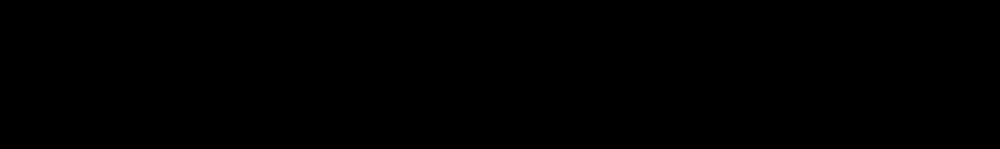
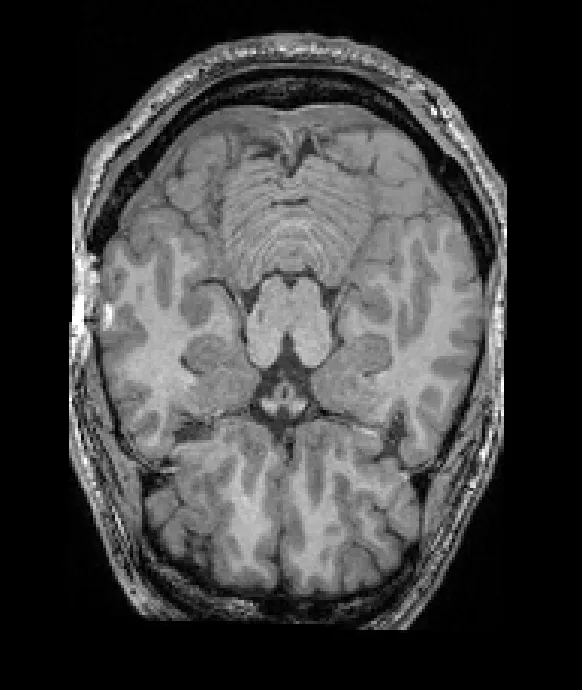
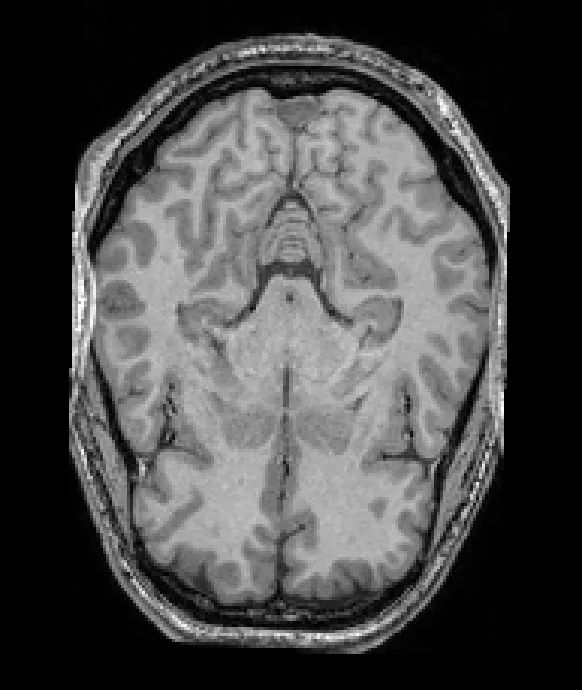
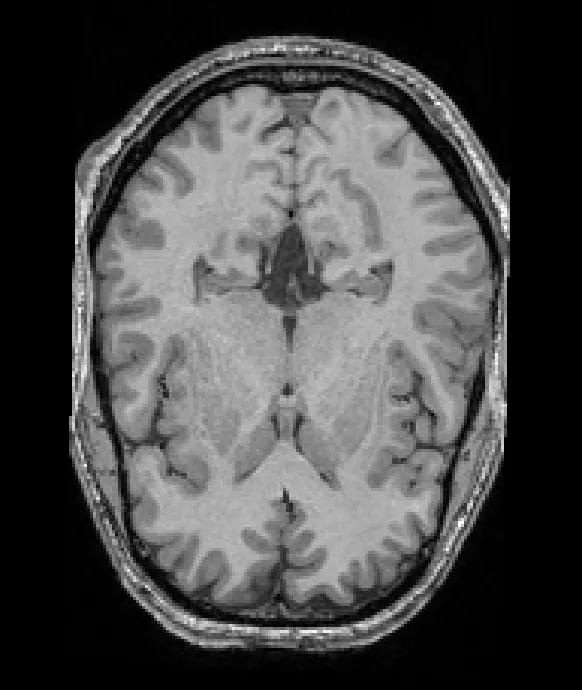
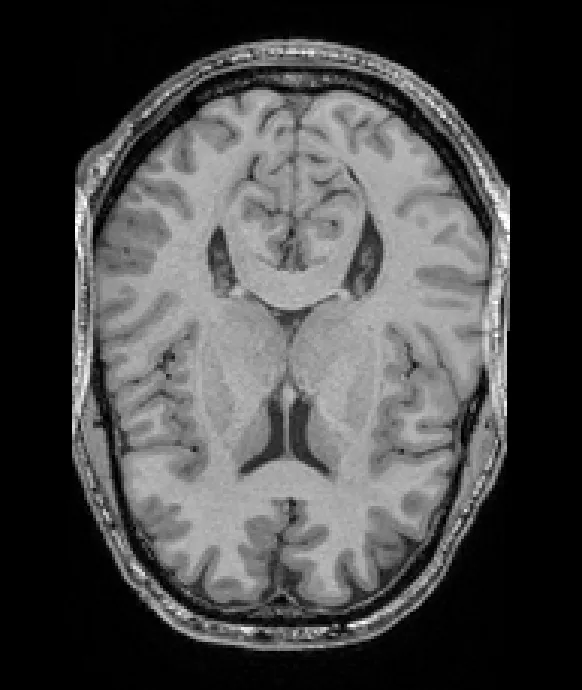
...
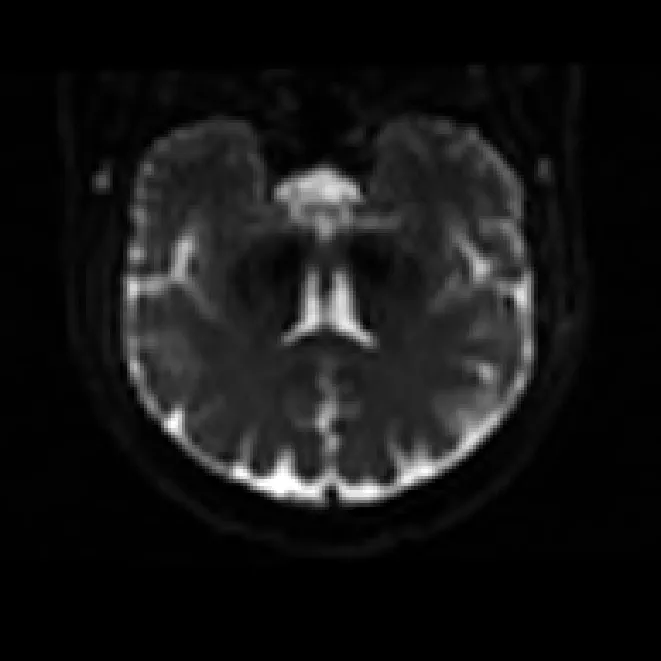
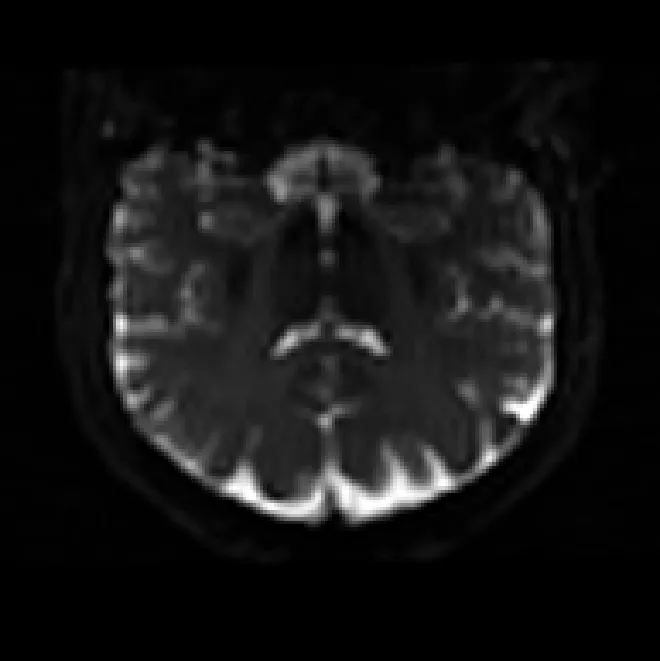
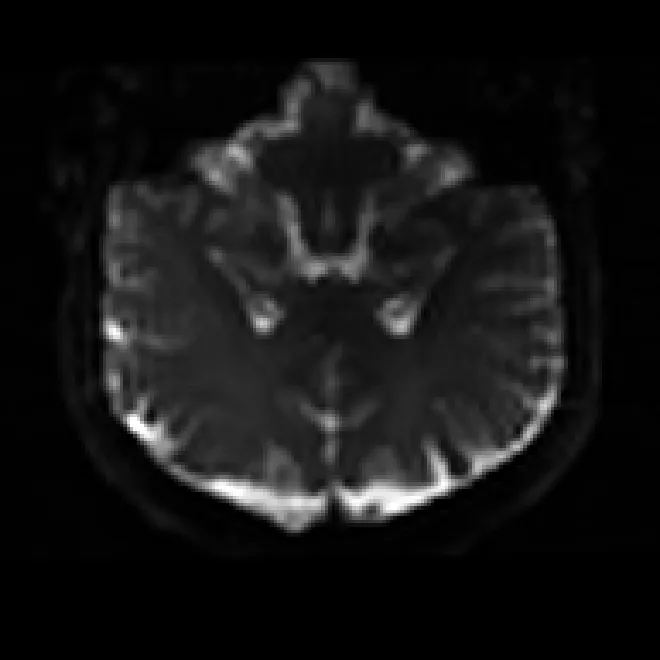
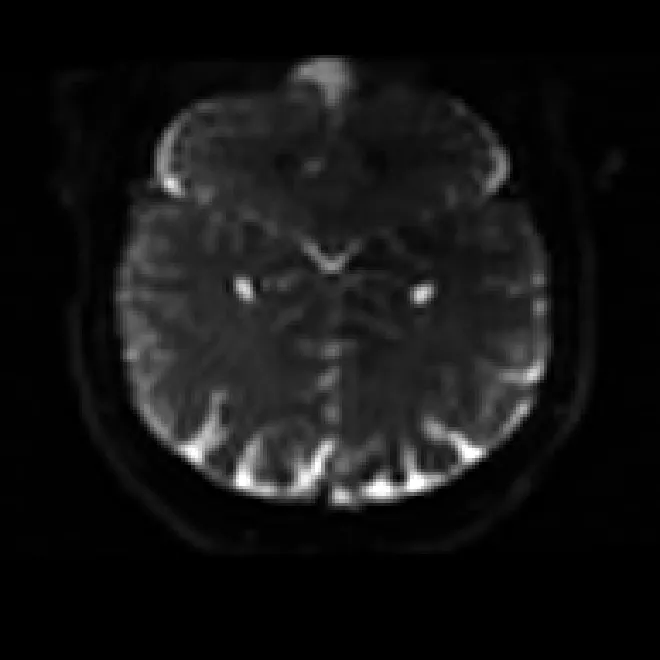
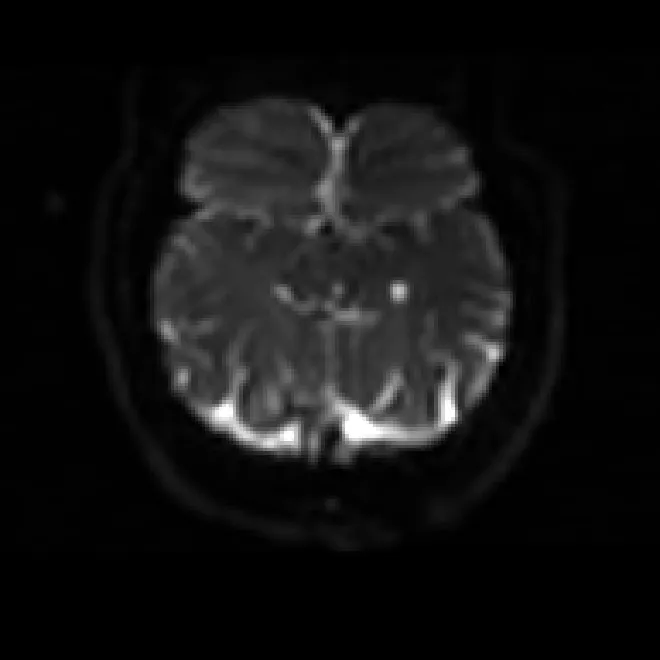

In [62]:
display_report('./qsiprep-output/sub-CON01.html')

## Dependencies in Jupyter/Python
- Using the package [watermark](https://github.com/rasbt/watermark) to document system environment and software versions used in this notebook, alongside the Neurodesktop version extracted from the `JUPYTER_IMAGE` or `NEURODESKTOP_VERSION` environment variables.

In [47]:
import os

%load_ext watermark

%watermark
%watermark --iversions

neurodesktop_version = (
    os.environ.get('JUPYTER_IMAGE', '').split(':')[-1] or
    os.environ.get('NEURODESKTOP_VERSION', 'unknown')
)

print(f"Neurodesktop version: {neurodesktop_version}")

Last updated: 2026-07-14T02:04:43.332852+00:00

Python implementation: CPython
Python version       : 3.13.13
IPython version      : 9.12.0

Compiler    : GCC 14.3.0
OS          : Linux
Release     : 5.15.0-177-generic
Machine     : x86_64
Processor   : x86_64
CPU cores   : 30
Architecture: 64bit

IPython  : 9.12.0
bs4      : 4.15.0
ipyniivue: 2.4.4
json     : 2.0.9

Neurodesktop version: 2026-06-13
